In [14]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from engine import (Board, ANNAgent, minimax_move, random_move, play_game,board_to_features, COLS)

random.seed(0); np.random.seed(0)

In [15]:
DATA = "connect4_dataset.csv"
if not os.path.exists(DATA):
    from generate_dataset import generate, save_csv
    save_csv(generate(30000, depth=5), DATA)

df = pd.read_csv(DATA)
print(df.shape)
df.head()

(69697, 43)


,c00,c01,c02,c03,c04,c05,c06,c07,c08,c09,...,c33,c34,c35,c36,c37,c38,c39,c40,c41,best_move
0,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,-1,1,1,-1,1,5
1,0,0,0,0,0,0,0,0,0,0,...,0,1,0,-1,0,0,0,0,1,3
2,-1,0,0,1,-1,0,0,1,0,0,...,0,-1,1,0,-1,-1,1,1,-1,6
3,0,-1,0,-1,1,0,1,0,-1,0,...,0,1,1,1,0,-1,1,-1,-1,0
4,0,0,1,-1,-1,0,1,-1,0,1,...,0,1,1,-1,1,1,-1,0,-1,1


Rows: 69697 | duplicates: 0 | missing values: 0


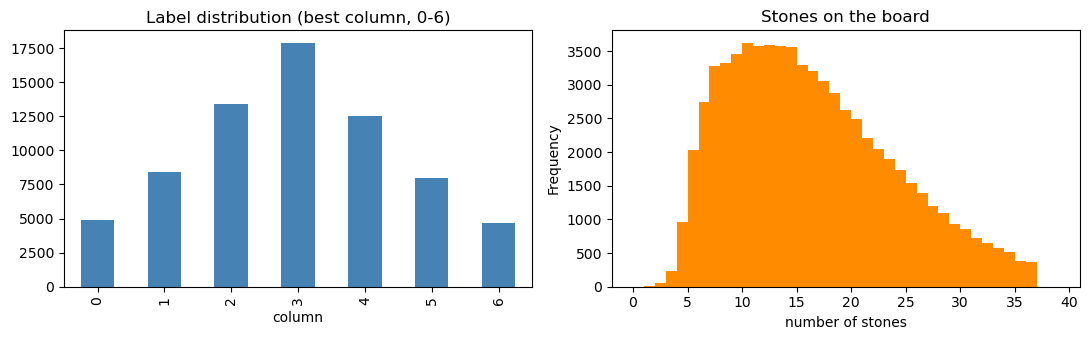

In [16]:
print("Rows:", len(df), "| duplicates:", df.drop(columns='best_move').duplicated().sum(),
      "| missing values:", int(df.isna().sum().sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df['best_move'].value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title("Label distribution (best column, 0-6)"); ax[0].set_xlabel("column")

stones = (df.drop(columns='best_move') != 0).sum(axis=1)
stones.plot.hist(bins=range(0, 40), ax=ax[1], color='darkorange')
ax[1].set_title("Stones on the board"); ax[1].set_xlabel("number of stones")
plt.tight_layout(); plt.show()

In [17]:
def show_row(i):
    arr = df.iloc[i, :42].values.astype(int).reshape(6, 7)
    sym = {1: 'X', -1: 'O', 0: '.'}          # X = player to move
    print("\n".join(" ".join(sym[v] for v in row) for row in arr))
    print("1 2 3 4 5 6 7")
    print("Teacher's best move: column", int(df.loc[i, 'best_move']) + 1, "\n")

for i in range(3):
    show_row(i)

. . . . . . .
. . . . . . .
. . . . . . .
. . . X . . .
. . O O O . X
. . O X X O X
1 2 3 4 5 6 7
Teacher's best move: column 6 

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . O
. . . . . . X
. O . . . . X
1 2 3 4 5 6 7
Teacher's best move: column 4 

O . . X O . .
X . . X O . X
O . . O O . O
X . . X X . X
O . . X O . O
X . O O X X O
1 2 3 4 5 6 7
Teacher's best move: column 7 



In [18]:
X42 = df.drop(columns='best_move').values
y = df['best_move'].values

def to_planes(X):
    return np.hstack([(X == 1).astype(float), (X == -1).astype(float)])

def mirror(X, y):
    return X.reshape(-1, 6, 7)[:, :, ::-1].reshape(-1, 42), 6 - y

idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.15, random_state=1, stratify=y)

Xm, ym = mirror(X42[tr], y[tr])
X_train = to_planes(np.vstack([X42[tr], Xm]))
y_train = np.concatenate([y[tr], ym])
X_test, y_test = to_planes(X42[te]), y[te]

print("train:", X_train.shape, "| test:", X_test.shape)

train: (118484, 84) | test: (10455, 84)


In [ ]:
ann = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),
    activation='relu',
    solver='adam',
    alpha=1e-4,
    batch_size=256,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=8,
    max_iter=200,
    random_state=1,
    verbose=False,
)
ann.fit(X_train, y_train)
print("Stopped after", ann.n_iter_, "epochs")

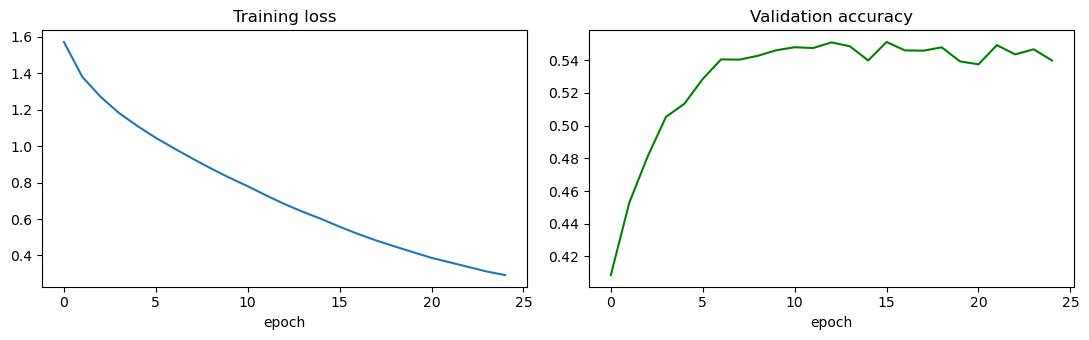

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ann.loss_curve_); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ann.validation_scores_, color='green'); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

Top-1 accuracy: 0.547
Top-2 accuracy: 0.765
Top-3 accuracy: 0.885


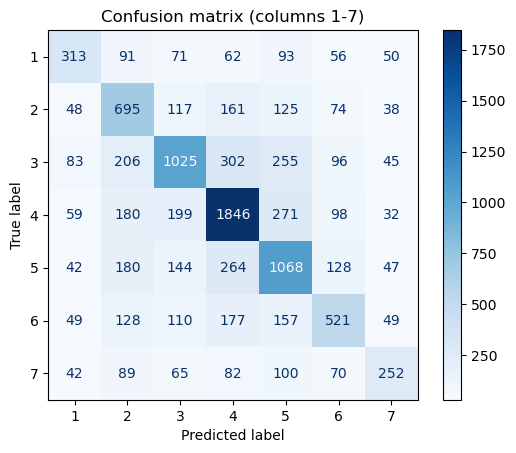

              precision    recall  f1-score   support

           0      0.492     0.425     0.456       736
           1      0.443     0.552     0.492      1258
           2      0.592     0.509     0.548      2012
           3      0.638     0.688     0.662      2685
           4      0.516     0.570     0.542      1873
           5      0.500     0.437     0.466      1191
           6      0.491     0.360     0.415       700

    accuracy                          0.547     10455
   macro avg      0.525     0.506     0.512     10455
weighted avg      0.548     0.547     0.545     10455



In [ ]:
pred = ann.predict(X_test)
proba = ann.predict_proba(X_test)
top = np.argsort(-proba, axis=1)

print(f"Top-1 accuracy: {(pred == y_test).mean():.3f}")
print(f"Top-2 accuracy: {np.mean([y_test[i] in top[i, :2] for i in range(len(y_test))]):.3f}")
print(f"Top-3 accuracy: {np.mean([y_test[i] in top[i, :3] for i in range(len(y_test))]):.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=range(1, 8)).plot(cmap='Blues')
plt.title("Confusion matrix (columns 1-7)"); plt.show()
print(classification_report(y_test, pred, digits=3))

In [ ]:
def noisy(player, eps):                    # make an opponent play a random move with prob. eps
    return lambda b: random_move(b) if random.random() < eps else player(b)

def match(agent_fn, opp_fn, n=60):
    '''ANN plays half the games as first player, half as second. Returns (wins, losses, draws).'''
    w = l = d = 0
    for i in range(n):
        if i % 2 == 0:
            r = play_game(agent_fn, opp_fn); w += r == 1; l += r == 2
        else:
            r = play_game(opp_fn, agent_fn); w += r == 2; l += r == 1
        d += r == 0
    return w, l, d

pure   = ANNAgent(ann, safety=False)
hybrid = ANNAgent(ann, safety=True)

opponents = {
    "random player":            random_move,
    "minimax depth 2 (15% noise)": noisy(lambda b: minimax_move(b, 2), 0.15),
    "minimax depth 4 (15% noise)": noisy(lambda b: minimax_move(b, 4), 0.15),
}
rows = []
for name, opp in opponents.items():
    for label, ag in (("pure ANN", pure), ("ANN + safety rule", hybrid)):
        w, l, d = match(ag.choose, opp)
        rows.append({"opponent": name, "agent": label, "wins": w, "losses": l, "draws": d})
pd.DataFrame(rows)

,opponent,agent,wins,losses,draws
0,random player,pure ANN,59,1,0
1,random player,ANN + safety rule,60,0,0
2,minimax depth 2 (15% noise),pure ANN,16,44,0
3,minimax depth 2 (15% noise),ANN + safety rule,24,36,0
4,minimax depth 4 (15% noise),pure ANN,25,34,1
5,minimax depth 4 (15% noise),ANN + safety rule,33,18,9


In [ ]:
joblib.dump(ann, "connect4_ann.joblib")
print("saved connect4_ann.joblib")

saved connect4_ann.joblib


In [ ]:
winner = play_game(hybrid.choose, lambda b: minimax_move(b, 2), verbose=False)
print({1: "ANN (X) won", 2: "minimax (O) won", 0: "draw"}[winner])

minimax (O) won


In [ ]:
from play import play_console
play_console(hybrid, human_first=True)

You are X - the ANN is the other symbol.
Enter a column number 1-7. Ctrl+C to quit.

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
1 2 3 4 5 6 7 

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
X . . . . . .
1 2 3 4 5 6 7 

ANN plays column 4

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
X . . O . . .
1 2 3 4 5 6 7 

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
X X . O . . .
1 2 3 4 5 6 7 

ANN plays column 5

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
X X . O O . .
1 2 3 4 5 6 7 

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . X . . .
X X . O O . .
1 2 3 4 5 6 7 

ANN plays column 6

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . X . . .
X X . O O O .
1 2 3 4 5 6 7 

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. X . X . . .
X X . O O O .
1 2 3 4 5 6 7 

ANN plays column 3

. . . . . . .
. . . . . . .
. . . .